# 03 · Why this verdict? Word-level explanations

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/maryammahmoudi1993/LSTM_emotion_recognition/blob/main/notebooks/03_word_level_explanations.ipynb)

**After this notebook you will be able to** explain a single prediction of the LSTM word by word with three different methods
(occlusion, LIME and integrated gradients), **test whether such explanations are faithful**, and say what they cannot tell you.

*Time: about 40 minutes (the cells run about four minutes on a laptop CPU in total). Prerequisites: notebooks 01 and 02.*

## 1 · The big question

The LSTM says a review is *negative* with 97% confidence. **Which words made it say so?**
Anyone who relies on a model (a film studio reading thousands of reviews, a doctor reading a risk score) wants more than a number:
they want to see the evidence, and to be warned when the model looks at the wrong thing.

Three ideas, in order of difficulty, each answering "how much did this word matter?":

1. **Occlusion** (cover the word): delete the word and see how much the prediction changes.
2. **LIME**: delete many random *groups* of words, record the model's answers, and fit a small, simple model that imitates the big one around this review.
3. **Integrated gradients**: slide the review from an "empty" input to the real one in small steps and add up how sensitive the output is to each word on the way.

> **Predict:** will the three methods agree on the most important words? And will deleting the words they pick change the prediction much more than deleting random words?

## 2 · Intuition and light math

**Analogy: a detective with a highlighter.** Occlusion asks each witness to leave the room and watches how the verdict changes.
LIME asks random groups of witnesses to leave, many times, and then tries to find a simple rule ("witness A matters a lot, witness B little") that predicts the verdicts.
Integrated gradients asks: "if I turn the volume of each witness up from silence to normal, which one makes the verdict move most?"

**Occlusion.** For a word $w$ in a review $x$, with $f(x)$ the probability of "positive":

$$\Delta_w = f(x) - f(x \setminus w)$$

- $x \setminus w$: the same review with every occurrence of $w$ deleted;
- $\Delta_w > 0$: the word pushed towards "positive", $\Delta_w < 0$: towards "negative".

**LIME.** It makes many variations $z$ of the review (each word kept, $z_i = 1$, or deleted, $z_i = 0$), asks the model for $f(z)$, and fits a weighted linear model

$$g(z) = w_0 + \sum_i w_i z_i \qquad \text{chosen to minimise} \quad \sum_z \pi(z)\,\big(f(z) - g(z)\big)^2 + \text{penalty}$$

- $w_i$: the weight of word $i$, which is the explanation (positive: towards "positive");
- $\pi(z)$: how close the variation $z$ is to the real review (close variations count more);
- the penalty keeps the model simple. The variations are random, so LIME has a *seed*.

**Integrated gradients.** Let $F$ be the model as a function of the word vectors $e$, and $e'$ an "empty" input (all vectors zero). For coordinate $i$:

$$\mathrm{IG}_i = (e_i - e'_i)\int_0^1 \frac{\partial F\big(e' + \alpha (e - e')\big)}{\partial e_i}\,d\alpha \;\approx\; (e_i - e'_i)\,\frac{1}{m}\sum_{k=1}^{m}\frac{\partial F}{\partial e_i}\Big|_{\alpha = k/m}$$

- $\alpha$ runs from 0 (empty input) to 1 (the real review), in $m$ steps (we use $m = 64$);
- $\partial F / \partial e_i$ ("the gradient"): how much the output changes if coordinate $i$ changes a little;
- we add up the scores of the 32 coordinates of a word to get one score per word;
- *completeness:* the scores of all words add up to $F(e) - F(e')$. We can check this numerically.

In [1]:
import os, pathlib, subprocess, sys

# On Google Colab the repository is not there yet, so we download it once.
if "google.colab" in sys.modules and not pathlib.Path("src").exists():
    subprocess.run(["git", "clone", "--depth", "1",
                    "https://github.com/maryammahmoudi1993/LSTM_emotion_recognition.git"], check=True)
    os.chdir("LSTM_emotion_recognition/notebooks")

sys.path.insert(0, str(pathlib.Path.cwd().resolve().parent))   # lets us import from src/

import time
import numpy as np
import matplotlib.pyplot as plt

from src import imdb_text as it
from src.imdb_text import save_figure

it.set_seed()                      # fixed seed (42): you should get the same numbers as the author
plt.rcParams["figure.dpi"] = 100

In [2]:
(x_train, y_train), (x_val, y_val), (x_test, y_test) = it.load_reviews(n_train=20000)
x_train_pad, x_val_pad, x_test_pad = it.pad(x_train), it.pad(x_val), it.pad(x_test)
mapping = it.word_to_id()

# the LSTM of notebook 01: same data, same seed, same settings -> same test accuracy
lstm, history = it.train("lstm", x_train_pad, y_train, x_val_pad, y_val)
print("test accuracy of the LSTM:", round(lstm.evaluate(x_test_pad, y_test, batch_size=256, verbose=0)[1], 4), "(notebook 01: 0.8626)")

test accuracy of the LSTM: 0.8626 (notebook 01: 0.8626)


**What to notice.** We explain exactly the model of notebook 01 (LSTM from scratch, seed 42). An explanation is only as good as the
model it explains: this one is right on about 86% of the reviews.

## 3 · A transparent reference: the word-counting model

A **linear** model is explained by its weights, no extra method needed. The bag-of-words logistic regression from notebook 01 gives
every word one weight: positive = pushes towards "positive".

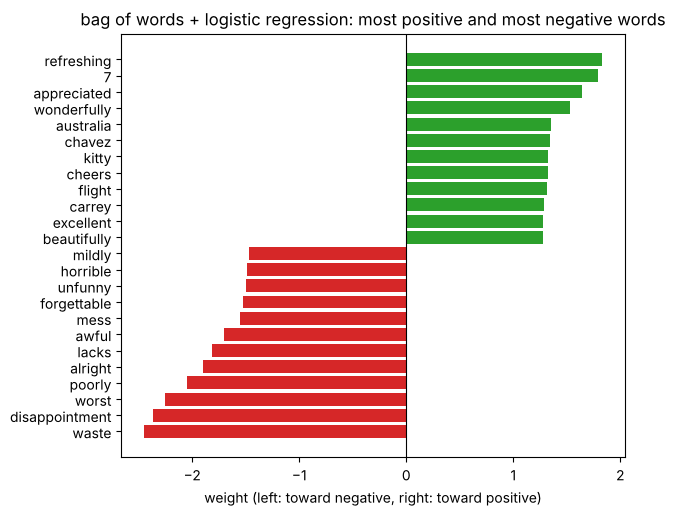

In [3]:
from sklearn.linear_model import LogisticRegression

counting = LogisticRegression(max_iter=1000).fit(it.bag_of_words(x_train), y_train)
inverse = it.id_to_word(mapping)
ids = np.array([i for i in range(3, it.VOCAB) if i in inverse])     # numbers that belong to a word
words = [inverse[i] for i in ids]
weights = counting.coef_[0][ids]

fig = it.plot_top_words(words, weights, "bag of words + logistic regression: most positive and most negative words")
save_figure(fig, "03_linear_weights.png")
plt.show()

**What to notice.** The most negative words are what you would expect: *waste*, *disappointment*, *worst*, *poorly*, *lacks*, *awful*, *mess*. The most positive include *wonderfully*, *excellent*, *beautifully*, *appreciated*, *refreshing*, but also **names and odd words** (*chavez*, *kitty*, *carrey*, *australia*, *flight*, *7*), and *alright* appears among the negative words.
A linear model reports what is correlated with the label in its training data, not what a word means: those names happen to occur in positive reviews among these 20,000. Reading the weights is an honest, complete ("global") explanation of *this* model, and also a warning about what it has learned.

*Figure: the 12 most negative (red) and 12 most positive (green) words of the word-counting model.*

## 4 · Explaining one review, three ways

We pick **40 short reviews** (25 to 60 words) from the test set: the first 40 that fit, in the order of the data set (no cherry-picking). We need *text*, so the reviews are rebuilt from the word numbers (lower case, no punctuation).
For each review and each method we compute a score per distinct word: positive = towards "positive".

In [4]:
texts, labels = it.full_text_reviews()
chosen = [i for i, t in enumerate(texts) if 25 <= len(it.tokenize(t)) <= 60][:40]
print("reviews selected:", len(chosen), "   true labels (1 = positive):", int(labels[chosen].sum()), "positive,", int(len(chosen) - labels[chosen].sum()), "negative")

start = time.time()
records = []
for i in chosen:
    review_words = it.tokenize(texts[i])
    p = float(it.probability_positive(lstm, [review_words], mapping)[0])
    token_scores, gap = it.integrated_gradients(lstm, review_words, mapping)
    records.append(dict(index=i, words=review_words, p=p, label=int(labels[i]), gap=gap, token_scores=token_scores,
                        occlusion=it.occlusion_scores(lstm, review_words, mapping),
                        ig=it.by_word(review_words, token_scores),
                        lime=it.lime_scores(lstm, review_words, mapping, seed=42)))
print(f"explained {len(records)} reviews with three methods in {time.time() - start:.0f} s")
accuracy = np.mean([(r['p'] > 0.5) == r['label'] for r in records])
print(f"the LSTM is right on {accuracy:.0%} of these {len(records)} reviews")

reviews selected: 40    true labels (1 = positive): 20 positive, 20 negative


explained 40 reviews with three methods in 61 s
the LSTM is right on 92% of these 40 reviews


In [5]:
record = records[0]
print("true label:", "positive" if record["label"] else "negative", "   p(positive) =", round(record["p"], 3))
print("review:", " ".join(record["words"]))
print()
for name in ["occlusion", "ig", "lime"]:
    scores = record[name]
    top = sorted(scores, key=lambda w: -abs(scores[w]))[:5]
    print(f"{name:10s}", ", ".join(f"{w} ({scores[w]:+.2f})" for w in top))
print(f"\nintegrated gradients, completeness check: the largest gap over all {len(records)} reviews is {max(abs(r['gap']) for r in records):.3f} (scores are in units of probability)")

true label: negative    p(positive) = 0.978
review: i saw this movie many years ago and just for kicks decided to rent it and watch it again the plot is a carbon copy from fright night i did like the hairy vampire and the bug eating driver otherwise it was not good at all

occlusion  fright (+0.05), and (+0.03), good (+0.02), kicks (+0.02), it (+0.02)
ig         fright (+0.16), and (+0.11), kicks (+0.10), plot (-0.10), it (+0.08)
lime       fright (+0.12), and (+0.07), plot (-0.07), good (+0.06), not (-0.06)

integrated gradients, completeness check: the largest gap over all 40 reviews is 0.018 (scores are in units of probability)


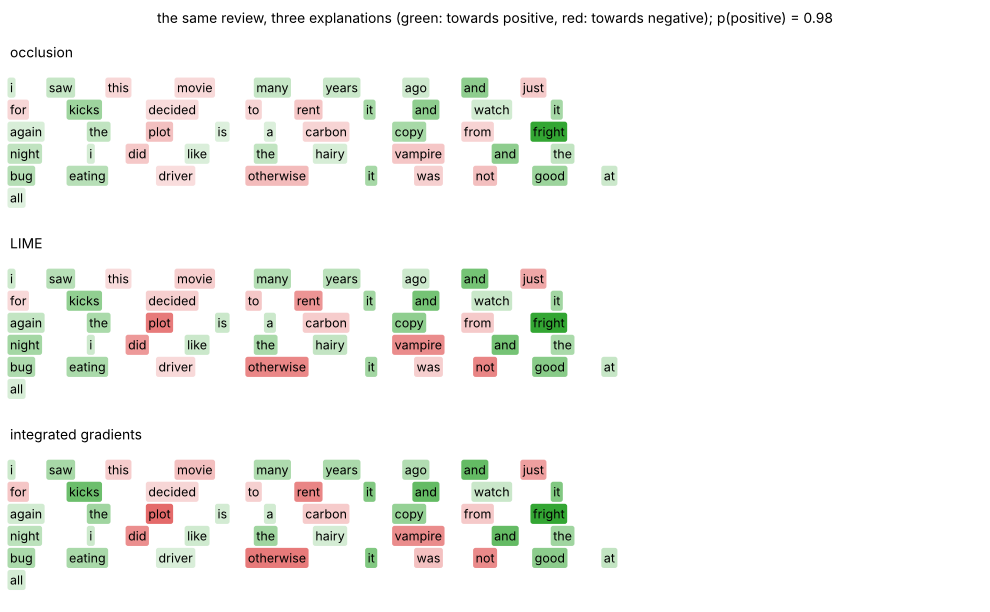

In [6]:
fig, axes = plt.subplots(3, 1, figsize=(10, 6.2))
for ax, (name, title) in zip(axes, [("occlusion", "occlusion"), ("lime", "LIME"), ("ig", "integrated gradients")]):
    scores = [record[name].get(w, 0.0) for w in record["words"]]
    it.draw_words(ax, record["words"], scores)
    ax.set_title(title, loc="left", fontsize=10)
fig.suptitle(f"the same review, three explanations (green: towards positive, red: towards negative); p(positive) = {record['p']:.2f}", fontsize=10)
fig.tight_layout()
save_figure(fig, "03_one_review.png")
plt.show()

**What to notice.** This review is **negative** (true label) but the LSTM says "positive" with 98%: it is **wrong**, and the explanations show why.

- All three methods agree on the strongest words. *fright* (as in the film *Fright Night*, a plot detail, not an opinion), *and* and *kicks* push towards "positive"; *plot*, *otherwise*, *vampire* and *rent* push towards "negative".
- The ending, *"it was not good at all"*, is the real verdict of the reviewer. In all three pictures *not* is red but *good* is green: the model does not read the phrase as a negation, and many weak green words add up to a confident "positive".
- So the explanation does what we wanted from it: it **reveals a failure** (the model leans on words that are not opinions and mishandles the negation), which the probability alone would never show.

*Figure: the same review explained by occlusion, LIME and integrated gradients; the more intense the colour, the larger the score.*

### Check yourself

1. In the occlusion formula, what does a negative $\Delta_w$ mean?
2. LIME gives a different answer when we change its seed. Why?

<details>
<summary>Answers</summary>


1. Deleting the word *raises* the probability of "positive", so the word was pushing the review towards "negative".
2. LIME deletes random groups of words, and different seeds give different random groups. The fitted weights therefore vary a little (or a lot, for reviews where the model is sensitive).

</details>

## 5 · Do the methods agree?

For every review we take the three most important words of each method (largest score in the direction of the model's verdict) and measure the overlap between the methods, as the share of words they have in common (3 = identical).

In [7]:
def top3(scores, p):
    sign = 1 if p > 0.5 else -1
    return set(sorted(scores, key=lambda w: -sign * scores[w])[:3])

pairs = [("occlusion", "ig"), ("occlusion", "lime"), ("ig", "lime")]
print("average number of shared words among the top 3 (out of 3):")
for a, b in pairs:
    shared = [len(top3(r[a], r["p"]) & top3(r[b], r["p"])) for r in records]
    print(f"  {a:10s} vs {b:10s}  {np.mean(shared):.2f}")

average number of shared words among the top 3 (out of 3):
  occlusion  vs ig          2.17
  occlusion  vs lime        2.20
  ig         vs lime        2.38


**What to notice.** On average the methods share between 2.2 and 2.4 of their three most important words (occlusion versus integrated gradients 2.17, occlusion versus LIME 2.20, integrated gradients versus LIME 2.38). If the words were picked at random we would expect far less than one shared word, so the methods largely agree, but not perfectly: roughly one word in four differs.

## 6 · Are the explanations faithful? A deletion test

Agreement between methods is not proof; they could all be wrong in the same way. A more direct test: **delete the 3 words a method calls most important** and see how much the model's confidence in its verdict drops.
If the explanation is faithful, the drop should be much larger than after deleting 3 *random* words. We also include the weights of the linear model from section 3 as a "method" (it explains a *different* model, so it tests whether the words that matter for counting also matter for the LSTM).

words deleted            mean drop median drop
occlusion                    0.302       0.236
integrated gradients         0.301       0.213
LIME                         0.291       0.240
linear model weights         0.241       0.151
3 random words               0.015       0.000


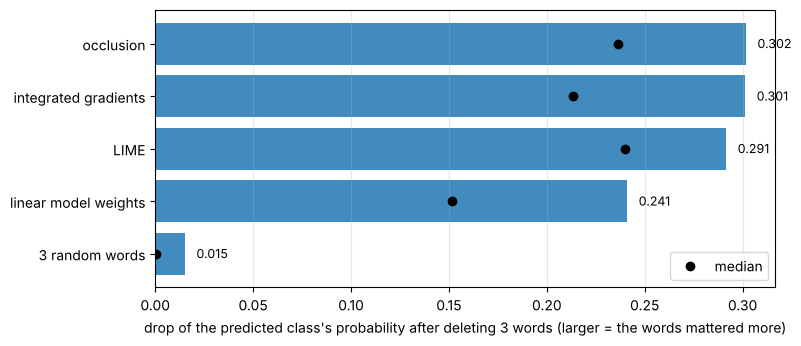

In [8]:
rng = np.random.default_rng(0)
linear = dict(zip(words, weights))
drops = {name: [] for name in ["occlusion", "integrated gradients", "LIME", "linear model weights", "3 random words"]}
for r in records:
    sign = 1 if r["p"] > 0.5 else -1
    distinct = list(dict.fromkeys(r["words"]))
    candidates = {"occlusion": r["occlusion"], "integrated gradients": r["ig"], "LIME": r["lime"],
                  "linear model weights": {w: linear.get(w, 0.0) for w in distinct}}
    choices = {name: sorted(scores, key=lambda w: -sign * scores[w])[:3] for name, scores in candidates.items()}
    choices["3 random words"] = list(rng.choice(distinct, 3, replace=False))
    for name, chosen_words in choices.items():
        after = float(it.probability_positive(lstm, [it.delete_words(r["words"], chosen_words)], mapping)[0])
        drops[name].append(sign * (r["p"] - after))

print(f"{'words deleted':24s} {'mean drop':>9s} {'median drop':>11s}")
for name, values in drops.items():
    print(f"{name:24s} {np.mean(values):9.3f} {np.median(values):11.3f}")

names = list(drops)
fig = it.plot_deletion(names, [np.mean(drops[n]) for n in names], [np.median(drops[n]) for n in names])
save_figure(fig, "03_deletion_test.png")
plt.show()

**What to notice.**

- Deleting the 3 words picked by **occlusion, integrated gradients or LIME** lowers the model's confidence in its verdict by about 0.29 to 0.30 on average (median 0.21 to 0.24), roughly twenty times more than deleting 3 random words (0.015, median 0.000). In this sense the three explanations are **faithful** to the model.
- Occlusion has an unfair advantage here: its score *is* the effect of deleting a word, so it is expected to do well in a deletion test. The informative result is that **integrated gradients and LIME, which work very differently, reach the same level**.
- The weights of the **linear model** (a different model!) also work, though less well (0.241, median 0.151): words that matter for counting mostly matter for the LSTM too.
- This test only checks whether the explanation describes the *model*. It does not tell us whether the model is right (it was wrong on the first review).

*Figure: average drop of the predicted class's probability after deleting 3 words chosen by each method (bars: mean, dots: median); 40 reviews.*

## 7 · How stable is LIME?

A good explanation should not depend on the luck of a random seed. We run LIME again with another seed on the first 10 reviews and compare the top 3 words.

In [9]:
shared = []
for r in records[:10]:
    again = it.lime_scores(lstm, r["words"], mapping, seed=7)
    shared.append(len(top3(r["lime"], r["p"]) & top3(again, r["p"])))
print("shared words among the top 3 for seed 42 versus seed 7 (10 reviews):", shared, "-> average", np.mean(shared))

shared words among the top 3 for seed 42 versus seed 7 (10 reviews): [3, 2, 3, 3, 3, 3, 3, 2, 3, 3] -> average 2.8


**What to notice.** With a second seed, LIME picked the same three words in 8 of the 10 reviews and two of the three words in the other 2 (average 2.8 of 3). On these short reviews and with 1,000 variations per review, LIME is fairly stable. We did not test longer reviews or fewer variations, where it would be less stable; always run it twice before reporting a LIME result.

## 8 · What these explanations can and cannot tell you

- **They explain the model, not the world.** "The word *waste* pushed the prediction towards negative" says what the LSTM did; it does not prove that the word *causes* a bad review.
- **They depend on the method and its settings.** Different methods give different (if often similar) rankings; LIME depends on a seed, integrated gradients on the chosen "empty" input, occlusion on how we delete words.
- **Deleting words creates unnatural text.** "this movie was good at all" is not a sentence the model saw during training, so the explanations rely on the model's behaviour in unfamiliar territory.
- **Words are not the whole story.** Our methods score single words; a negation ("not good") is a pair, and the effect of a word can depend on others.
- **A faithful explanation can still be a wrong model.** The test in section 6 measures whether the explanation describes the *model*; it says nothing on whether the model is right.
- **Small test.** 40 short reviews, one model, one seed. The numbers show the trend, not a general law.

## 9 · Common mistakes

- **Believing a pretty picture.** Always test an explanation (as in section 6) before trusting it.
- **Explaining one example and generalising.** Look at many reviews, including the ones the model gets wrong.
- **Ignoring the seed of LIME.** Run it twice; if the answer changes, say so.
- **Mixing up "important to the model" with "important in reality".**

## 10 · Recap

- Occlusion, LIME and integrated gradients each give every word a score; positive means towards the model's "positive".
- A deletion test turns "this looks plausible" into a measurable check of faithfulness.
- Explanations describe the model, can be unstable, and always need their limits stated.

**Next:** this was the last notebook. The README of the repository collects the whole path and the honest results.